<a href="https://colab.research.google.com/github/Abidau/MachineLearning/blob/main/TG11_Klasifikasi_244107020212_NaufalAbidAurizky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Praktikum 1

### Langkah 1 - Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### Langkah 2 - Membuat Data Dummy

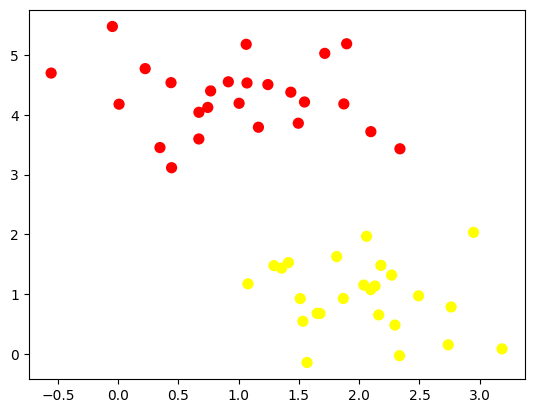

In [ ]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3 - Buat Ilustrasi Garis Pemisah

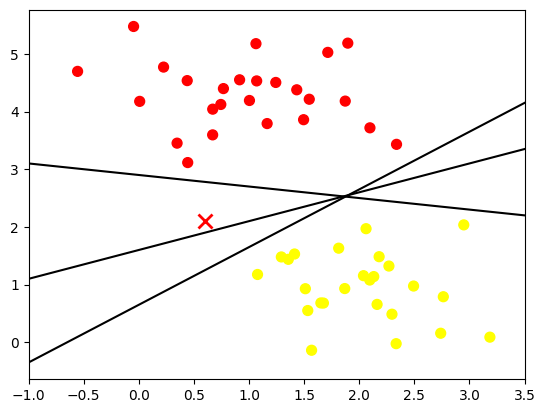

In [ ]:
xfit = np.linspace(-1, 3.5)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.show()

### Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

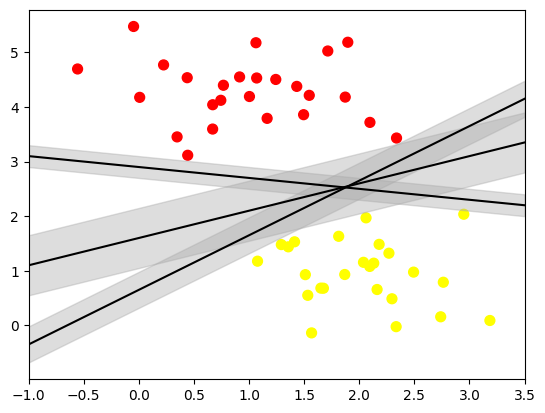

In [ ]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

### Langkah 5 - Fitting Model

In [ ]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

Membuat fungsi untuk membantu visualisasi hasil fit model

In [ ]:
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

Melakukan plotting dengan fungsi yang telah dibuat

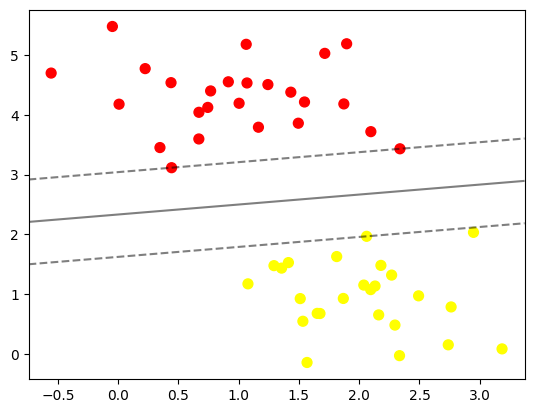

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

In [ ]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

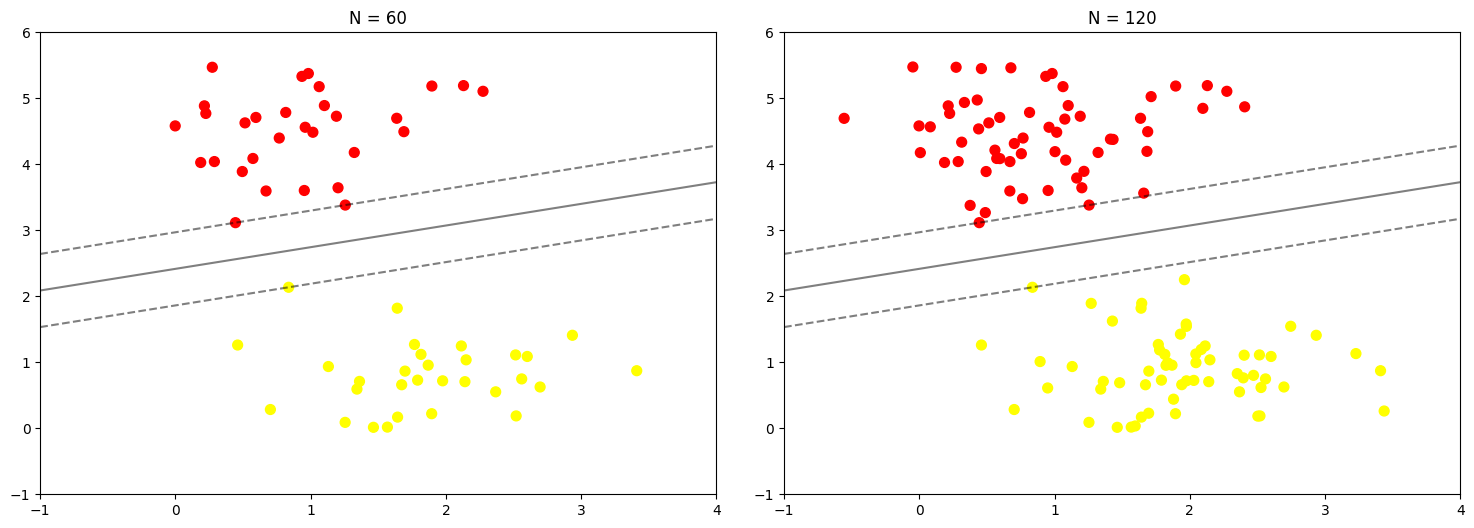

In [ ]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

In [ ]:
from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

## Praktikum 2

### Langkah 1 - Ilustrasi Data Non-Linier
#### Langkah 1a - Import Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

#### Langkah 1b - Buat Kembali Fungsi Plotting

In [ ]:
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### Langkah 1c - Buat Data Dummy Non-Linier

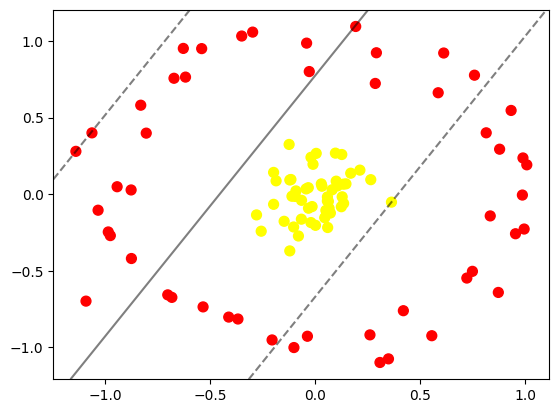

In [ ]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1, random_state=2725)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [ ]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# proyeksi radial (dimensi ketiga)
r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    plt.figure()  # buat figure baru agar plot tidak bertumpuk
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-4.19325093e-02,  9.85284187e-01],
       [-9.76885578e-01, -2.70533553e-01],
       [-2.13300316e-02, -1.85468905e-01],
       [-7.03304503e-01, -6.57135373e-01],
       [-2.98931937e-01,  1.05718998e+00],
       [ 3.07466796e-01, -1.09837941e+00],
       [ 9.89891554e-02,  8.46207647e-02],
       [ 1.68223438e-01,  1.36514669e-01],
       [ 3.62237538e-01, -5.22234475e-02],
       [-9.27337938e-02,  2.11169723e-02],
       [ 1.91914379e-01,  1.09393473e+00],
       [-1.02296571e-01, -1.00094706e+00],
       [ 3.47977909e-01, -1.07478358e+00],
       [-4.12894361e-01, -8.02245242e-01],
       [ 4.98982953e-02, -1.06049706e-01],
       [ 4.18894421e-01, -7.60556155e-01],
       [-6.68565007e-02, -1.63456202e-01],
       [-3.51063619e-01,  1.03158429e+00],
       [-3.28813800e-02, -9.18560134e-02],
       [-6.18746929e-01,  7.63623425e-01],
       [-1.21936476e-01,  9.24000564e-02],
       [-1.22060923e-01, -3.70367774e-01],
       [ 2.11824667e-01,  1.56689906e-01],
       [ 8.13506784e-01,  4.00132025e-01],
       [ 1.23431727e-01, -8.20832735e-02],
       [ 4.43956080e-02, -1.53862804e-01],
       [-1.03514415e+00, -1.04881622e-01],
       [ 7.96408836e-02,  2.84785914e-02],
       [-6.62188592e-02, -4.03264985e-02],
       [-2.58269377e-01, -2.41850417e-01],
       [-2.80480229e-01, -1.35455888e-01],
       [ 9.52991223e-02,  2.67491574e-01],
       [-1.11782267e-01, -1.37732260e-02],
       [ 8.77383210e-01,  2.93193078e-01],
       [-8.05782613e-01,  3.97980190e-01],
       [ 7.12144347e-02, -1.23123490e-01],
       [-9.44470230e-01,  4.82950498e-02],
       [ 3.11860437e-02,  5.17052359e-02],
       [ 6.17632191e-02, -4.68507540e-02],
       [ 2.63696197e-01,  9.43294456e-02],
       [ 1.45476674e-01,  6.70493625e-02],
       [-8.08891873e-02, -2.73084533e-01],
       [ 3.92016026e-04, -2.03447141e-01],
       [ 9.94171273e-01, -2.27737456e-01],
       [-9.56706336e-02, -1.50802838e-02],
       [ 1.33316063e-01,  6.49009990e-02],
       [ 8.71187963e-01, -6.41399781e-01],
       [-8.77816858e-01,  2.72752069e-02],
       [-2.06399747e-01, -9.51323133e-01],
       [-2.10665192e-02,  2.40202880e-01],
       [ 2.90442371e-01,  9.22474389e-01],
       [-4.43562361e-02,  3.41100942e-02],
       [-1.14085874e+00,  2.79244505e-01],
       [ 5.84779908e-01,  6.61561101e-01],
       [ 7.47865370e-01, -5.03716773e-01],
       [-1.25226529e-01,  3.24197746e-01],
       [ 9.85791318e-01, -5.95207768e-03],
       [ 9.53059939e-01, -2.58394884e-01],
       [ 7.57623292e-01,  7.76074679e-01],
       [-3.68980682e-01, -8.14764959e-01],
       [-1.09272971e+00, -6.98078524e-01],
       [ 2.80739743e-02,  6.68258245e-02],
       [-1.06437039e+00,  3.99736626e-01],
       [ 2.85201861e-01,  7.22273689e-01],
       [-6.73604803e-01,  7.56052885e-01],
       [ 6.11082806e-01,  9.20794472e-01],
       [ 5.84017109e-02, -2.17788470e-01],
       [-1.87296959e-01,  8.68915872e-02],
       [-2.92782344e-02,  7.99804142e-01],
       [ 5.69798875e-02, -4.44714304e-02],
       [ 1.34305967e-01, -6.05016853e-02],
       [-1.58279808e-02, -8.11342751e-02],
       [-1.16532876e-01,  9.54743717e-02],
       [-9.86635952e-01, -2.46738296e-01],
       [-1.49023000e-01, -1.77227379e-01],
       [-3.39842746e-02,  4.19997433e-02],
       [ 8.32685982e-01, -1.42078437e-01],
       [ 2.59779876e-01, -9.18229708e-01],
       [ 6.50841226e-02, -9.23356543e-02],
       [ 1.25591459e-01,  2.58553869e-01],
       [-3.80745697e-02, -9.27268993e-01],
       [-1.03689443e-01, -2.14335864e-01],
       [ 3.80335709e-03,  2.66013867e-01],
       [ 9.88549624e-01,  2.36108850e-01],
       [-6.29176594e-01,  9.50804074e-01],
       [ 9.32104770e-01,  5.46085104e-01],
       [ 1.04911765e-01,  5.35810967e-02],
       [ 1.27463580e-01, -1.75298984e-02],
       [-8.31938252e-01,  5.80244806e-01],
       [ 1.00685046e+00,  1.91299773e-01],
       [-5.35076826e-01, -7.35746943e-01],
       [-1.99115730e-01, -6.65130618e-02

### Langkah 2 - Fitting Model

In [ ]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

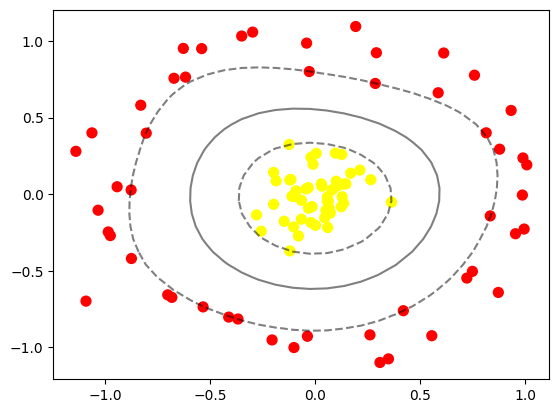

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none');

## Praktikum 3

### Langkah 1 - Import Library dan Buat Fungsi Plotting

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 2 - Buat Data Dummy

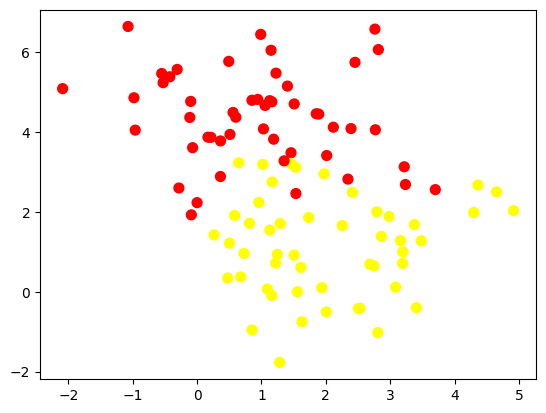

In [3]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

### Langkah 3 - Analisis Dampak Tunning

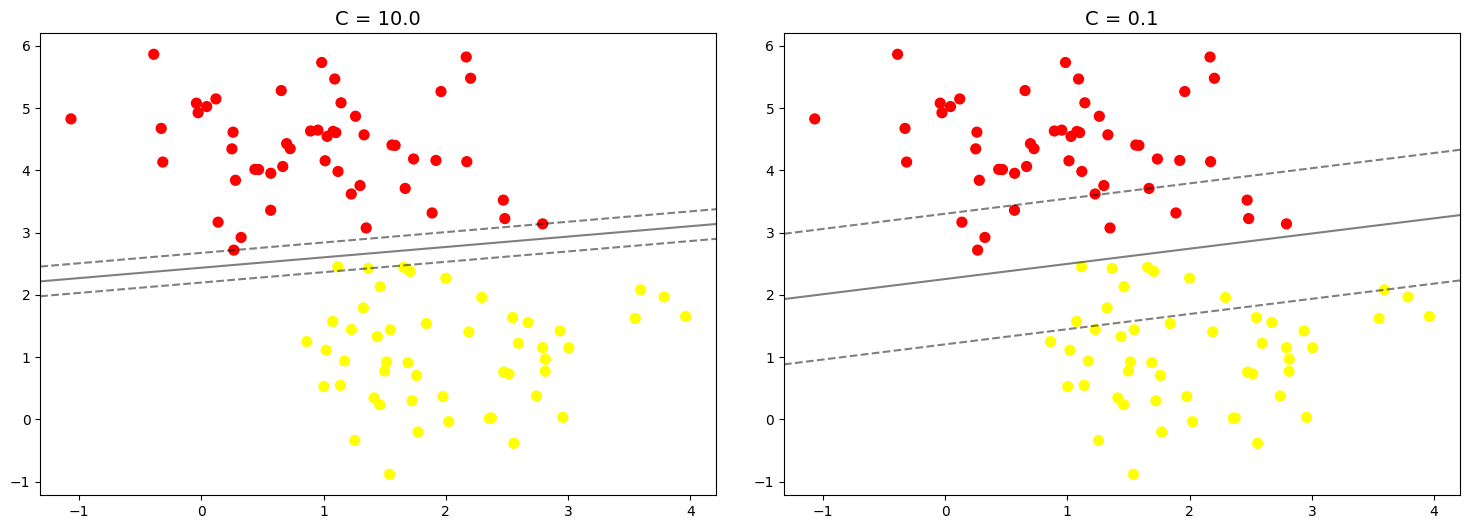

In [4]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

## Praktikum 4

### Langkah 0 - Unduh Dataset

In [5]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


### Langkah 1 - Inspeksi Citra Wajah

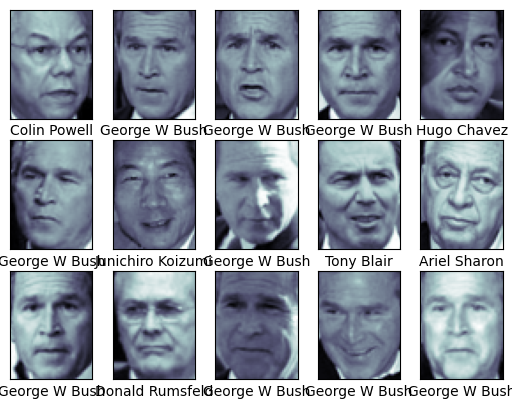

In [6]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

### Langkah 2 - Pra Pengolahan Data

In [7]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

### Langkah 3 - Split Data

In [8]:
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

### Langkah 4 - Pembuatan Model + Tunning

In [9]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 8s, sys: 203 ms, total: 2min 8s
Wall time: 1min 20s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [10]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

### Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

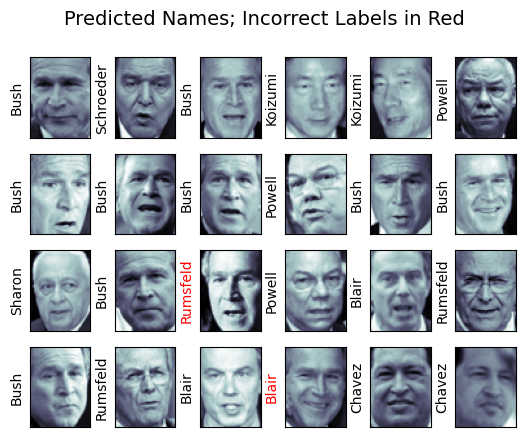

In [11]:
fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

### Langkah 6 - Cek Performansi

In [12]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

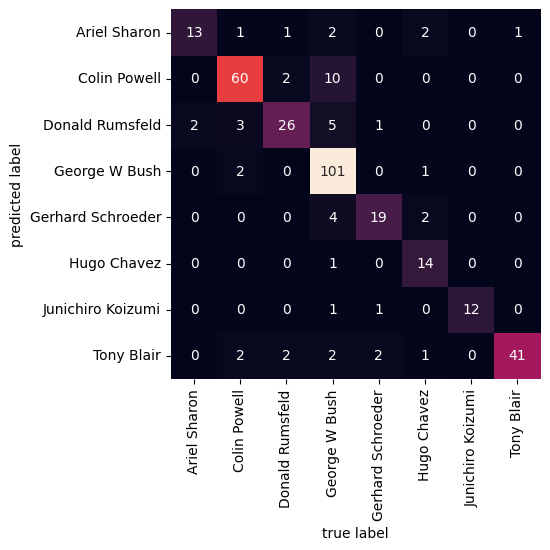

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

## Praktikum 5

## Langkah 0 - Import Library

In [19]:
import zipfile

zip_path = "/content/images.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall("/content/")

In [20]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [21]:
train_dir = "images/training/"
test_dir = "images/test/"

### Langkah 1 - Load Data dan Visualisasikan

In [22]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

Load gambar training

In [23]:
train_img = load_dataset(train_dir)

In [24]:
train_img[0]

(array([[[10, 15, 18],
         [ 1,  6,  9],
         [26, 30, 31],
         ...,
         [ 6,  7,  2],
         [14, 15, 10],
         [ 9, 10,  5]],
 
        [[13, 17, 20],
         [ 4,  8, 11],
         [23, 27, 28],
         ...,
         [10, 11,  6],
         [13, 14,  9],
         [ 3,  4,  0]],
 
        [[17, 18, 22],
         [ 8,  9, 13],
         [22, 23, 25],
         ...,
         [ 9, 10,  5],
         [12, 13,  8],
         [ 0,  1,  0]],
 
        ...,
 
        [[11, 10,  6],
         [ 1,  0,  0],
         [27, 26, 22],
         ...,
         [ 0,  4,  0],
         [ 7, 14,  7],
         [11, 21, 13]],
 
        [[31, 30, 26],
         [ 1,  0,  0],
         [ 6,  5,  1],
         ...,
         [ 8, 15,  8],
         [33, 40, 33],
         [39, 49, 41]],
 
        [[14, 13,  9],
         [ 6,  5,  1],
         [26, 25, 21],
         ...,
         [ 0,  7,  0],
         [19, 26, 19],
         [ 5, 12,  5]]], dtype=uint8),
 'night')

Mengecek ukuran gambar secara acak

In [27]:
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 117
(531, 800, 3)


In [28]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Melakukan visualisasi gambar secara acak

Shape	: (372, 640, 3)
Label	: night


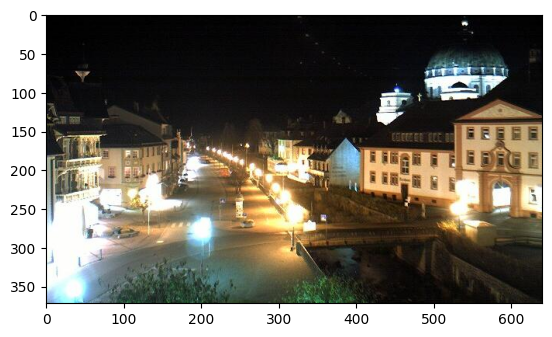

In [29]:
random_img_viz(train_img)

### Langkah 3 - Pra Pengolahan Data

In [30]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

Membuat fungsi untuk kebutuhan encoding label

In [31]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [32]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

Melakukan pra pengolahan data pada data training

In [33]:
train_std_img_list = preprocess(train_img)

Melakukan pengecekan ukuran gambar secara acak

In [34]:
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 231
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 0


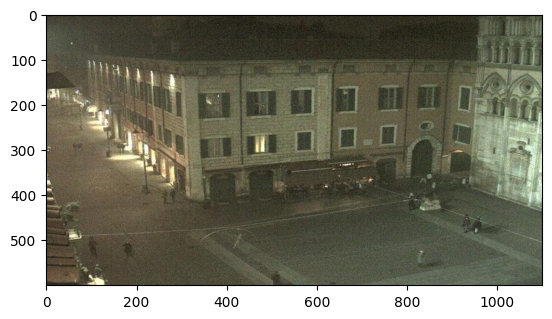

In [35]:
random_img_viz(train_std_img_list)

### Langkah 4 - Ekstraksi Fitur

In [36]:
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 231
Avg Brighness: 144.0751


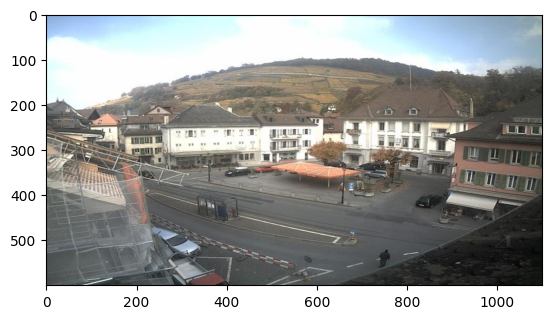

In [43]:
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

### Langkah 5 - Klasifikasi dengan Metode Threshold

In [44]:
def predict_label(img, threshold):
    # Computer average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Melakukan pengecekan prediksi secara acak pada data training

Image 77
Actual label: 0
Predicted label: 0


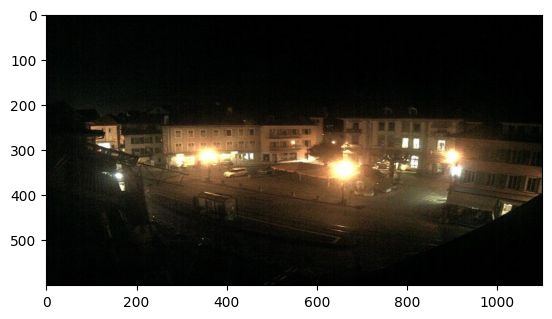

In [45]:
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

### Langkah 6 - Evaluasi Manual

In [46]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

Melakukan evaluasi pada data training dengan nilai ambang batas 120

In [47]:
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [48]:
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Predict
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


### Langkah 4 Alternatif - Membuat Feature Vectors

In [49]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
        img_label = img[1] # Get the image label

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columcular way
    data = np.column_stack((avg_list, labels))
    # Create a Pandas dataframe
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

Mengecek hasilnya pada data training

In [52]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,26.946276,0.0
1,114.386045,0.0
2,36.167309,0.0
3,89.905798,0.0
4,48.713038,0.0


Melakukan langkah yang serupa pada data testing

In [53]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,37.642245,0.0
1,38.777894,0.0
2,26.358703,0.0
3,41.211485,0.0
4,53.467780,0.0


### Langkah 5 - Buat Model SVM

In [54]:
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

### Langkah 6 - Evaluasi

In [55]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)

# Get the accuracy on train data
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)

# Get the accuracy on test data
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


## Tugas Praktikum

### 1. SVM pada voice.csv

In [58]:
df = pd.read_csv('voice.csv')
X = df.drop('label', axis=1)
y = df['label']

hasil = []

for rasio in [0.3, 0.2]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=rasio, random_state=42)

    # scaling fitur
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    for kernel in ['linear', 'poly', 'rbf']:
        model = SVC(kernel=kernel)
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        hasil.append([f'{int((1-rasio)*100)}:{int(rasio*100)}', kernel, acc])

tabel = pd.DataFrame(hasil, columns=['Split', 'Kernel', 'Akurasi'])
print(tabel)
print(tabel.pivot(index='Kernel', columns='Split', values='Akurasi'))

   Split  Kernel   Akurasi
0  70:30  linear  0.970557
1  70:30    poly  0.957939
2  70:30     rbf  0.981073
3  80:20  linear  0.976341
4  80:20    poly  0.971609
5  80:20     rbf  0.982650
Split      70:30     80:20
Kernel                    
linear  0.970557  0.976341
poly    0.957939  0.971609
rbf     0.981073  0.982650


### 2. Klasifikasi siang atau malam dengan histogram

In [59]:
data = []
label = []

for sub in ['training', 'test']:
    for nama in ['day', 'night']:
        for f in Path(f'images/{sub}/{nama}').glob('*.jpg'):
            img = cv2.imread(str(f))
            img = cv2.resize(img, (1100, 600))
            hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

            # histogram channel V (kecerahan), 32 bin
            hist = cv2.calcHist([hsv], [2], None, [32], [0, 256]).flatten()
            hist = hist / hist.sum()

            data.append(hist)
            label.append(1 if nama == 'day' else 0)

X = np.array(data)
y = np.array(label)
print(X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = SVC(kernel='rbf')
model.fit(X_train, y_train)
print('Akurasi default:', accuracy_score(y_test, model.predict(X_test)))

param = {'C': [0.1, 1, 10, 100, 1000],
         'gamma': ['scale', 0.001, 0.01, 0.1, 1, 10]}

grid = GridSearchCV(SVC(kernel='rbf'), param, cv=5)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
print('Akurasi tuning:', accuracy_score(y_test, grid.predict(X_test)))

(400, 32)
Akurasi default: 1.0
Parameter terbaik: {'C': 10, 'gamma': 'scale'}
Akurasi tuning: 1.0
